<a href="https://colab.research.google.com/github/Cpea8713/Lab1/blob/main/assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [ ]:
# Add code here 🔧
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
df = pd.read_csv("https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv")
display(df.head())
display(df.describe())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. About 25% were canceled, and most bookings were made around 79 days in advance on average. I also noticed that some columns have missing information.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [ ]:
# Add code here 🔧
df = df.drop_duplicates()
df = df[df['lead_time'] <= 500]
df = df[df['adr'] >= 0]
features = ['lead_time', 'stays_in_weekend_nights','stays_in_week_nights', 'adr','total_of_special_requests']
X = df[features].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 3.64815128, -1.03157493, -1.29624903, -1.6373468 , -0.80191271],
       [-0.76013057, -1.03157493, -0.88430051, -0.28654662, -0.80191271],
       [-0.68117627, -1.03157493, -0.88430051, -0.28654662, -0.80191271],
       ...,
       [-0.85224393, -1.03157493, -0.88430051, -0.95294137, -0.80191271],
       [-0.70749437, -1.03157493, -0.88430051, -0.66477067,  0.36479403],
       [-0.85224393, -1.03157493, -0.88430051, -0.95294137, -0.80191271]],
      shape=(7727, 5))

### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I chose lead time, weekend nights, week nights, average daily rate, and special requests because they show how people book hotels and what they might want.

2. I expect to find groups like people who book early, people who stay longer, and people who spend more money.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

cluster
1    3344
0    1902
3    1667
2     814
Name: count, dtype: int64


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
0,79.176130,2.398002,5.822818,107.898985,0.451104
1,19.015849,0.456041,1.500897,64.599844,0.328648
2,232.600737,1.491400,3.964373,69.846622,0.412776
3,58.139772,1.071386,2.995201,134.588680,1.810438


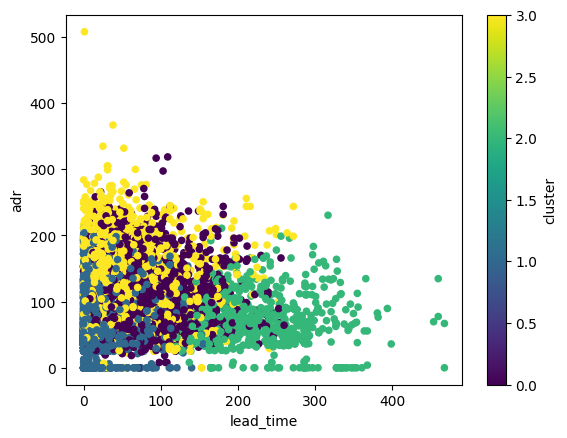

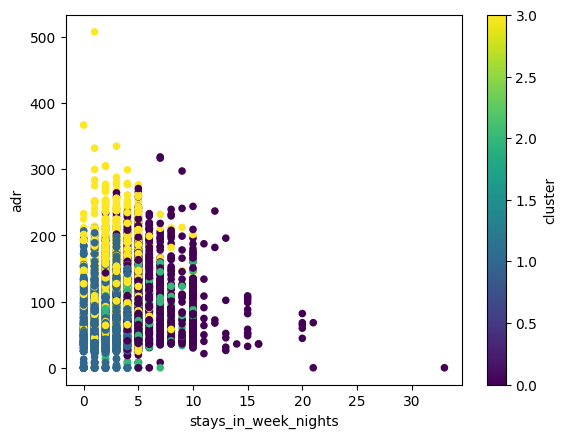

In [ ]:
# Add code here 🔧
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
X = X.copy()
X['cluster'] = clusters
print(X['cluster'].value_counts())
X.plot.scatter(x='lead_time', y='adr', c='cluster', colormap='viridis')
X.plot.scatter(x='stays_in_week_nights', y='adr',c='cluster', colormap='viridis')
X.groupby('cluster').mean()

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose 4 clusters because I thought it would give us a good number of groups without making it too complicated.

2. Cluster 0 has people who stay longer. Cluster 1 has shorter stays and lower prices. Cluster 2 has people who book really far in advance. Cluster 3 has people who spend more and make more special requests.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

gmm_cluster
2    2935
1    1938
0    1576
3    1278
Name: count, dtype: int64
[[0.00000000e+00 4.38441425e-06 6.39039389e-46 9.99995616e-01]
 [6.22565499e-01 6.26981266e-03 3.66534755e-01 4.62993301e-03]
 [5.48179112e-05 1.71897829e-02 9.69611049e-01 1.31443498e-02]
 [9.45885090e-06 1.86351124e-01 8.09159179e-01 4.48023779e-03]
 [6.22374891e-01 8.90619692e-03 3.65573110e-01 3.14580234e-03]]


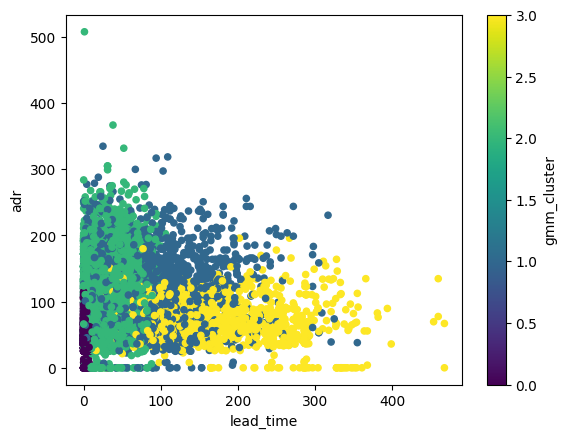

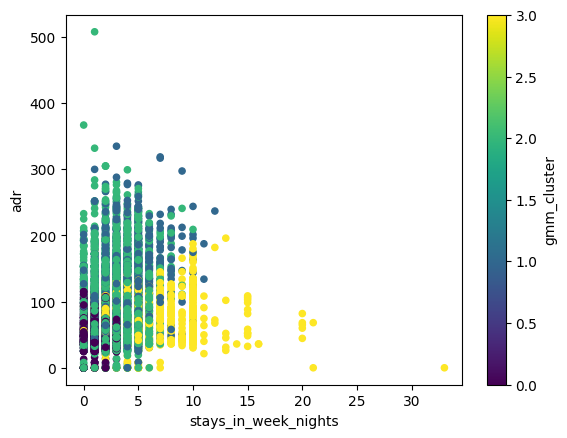

In [ ]:
# Add your code here
gmm = GaussianMixture(n_components=4, random_state=42)
gmm_clusters = gmm.fit_predict(X_scaled)
X['gmm_cluster'] = gmm_clusters
print(X['gmm_cluster'].value_counts())
X.plot.scatter(x='lead_time', y='adr',c='gmm_cluster', colormap='viridis')
X.plot.scatter(x='stays_in_week_nights', y='adr',c='gmm_cluster', colormap='viridis')
X.groupby('gmm_cluster')[features].mean()
gmm_probabilities = gmm.predict_proba(X_scaled)
print(gmm_probabilities[:5])

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM made different groups than KMeans, but both showed patterns in how people booked hotels. GMM seemed to separate people more based on when they booked and how long they stayed.

2. GMM could help hotels figure out which customers book early, which ones spend more money, and which ones make more special requests.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [ ]:
# Add code here 🔧
kmeans_sil = silhouette_score(X_scaled, clusters)
gmm_sil = silhouette_score(X_scaled, gmm_clusters)
kmeans_db = davies_bouldin_score(X_scaled, clusters)
gmm_db = davies_bouldin_score(X_scaled, gmm_clusters)
print("KMeans Silhouette:", kmeans_sil)
print("GMM Silhouette:", gmm_sil)
print("KMeans Davies-Bouldin:", kmeans_db)
print("GMM Davies-Bouldin:", gmm_db)
print("KMeans WCSS:", kmeans.inertia_)
print("GMM WCSS:", ((X_scaled - gmm.means_[gmm_clusters])**2).sum())

KMeans Silhouette: 0.28839930147482445
GMM Silhouette: 0.12209980812064063
KMeans Davies-Bouldin: 1.374281890535638
GMM Davies-Bouldin: 1.7437821161572853
KMeans WCSS: 20074.163413090213
GMM WCSS: 24159.21843405515


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans had a better silhouette score and Davies-Bouldin score than GMM. Based on these results, KMeans seems to work better for this data.

5.3. I would recommend KMeans because it had better scores and was easier to understand. I think it would be simpler for a business to use.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [ ]:
# Add code here 🔧
cluster_summary = X.groupby('cluster')[features].mean()
cluster_summary.sort_values('lead_time')

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
1,19.015849,0.456041,1.500897,64.599844,0.328648
3,58.139772,1.071386,2.995201,134.588680,1.810438
0,79.176130,2.398002,5.822818,107.898985,0.451104
2,232.600737,1.491400,3.964373,69.846622,0.412776


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The groups show different types of guests. Some book early, some stay longer, and others spend more money or make more special requests.

2. The hotel could offer discounts for early bookings, deals for longer stays, and special packages for customers who spend more money.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. I think the hardest part was figuring out how many clusters to use and understanding what the different groups meant.

2. I would use clustering when I want to find groups or patterns in data without already knowing what the answers should be.

3. I would explain that clustering helps us group similar customers together so we can better understand them and make better business decisions.

4. My learning outcome was about using data to make better decisions in real estate. This assignment helped me learn how to group similar properties together, which could help me compare houses and make better investment decisions.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 719987 bytes to assignment_09_clustering.html
